# Partie 0. Rappels de maths et prise en main de Python

Vérifier les calculs de sommes, d'intégrales et d'équations avec SymPy, puis découvrir NumPy, SciPy et la simulation.

*Cours « Probabilités pour la gestion des risques », M1 GRAF. Exécutez les cellules dans l'ordre (Maj + Entrée).*

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, integrate
from math import comb, perm, factorial, log, exp

rng = np.random.default_rng(42)   # graine : memes resultats a chaque execution

## 0.1 à 0.4 : Rappels de maths avec SymPy
SymPy calcule de façon **exacte**, comme à la main.

In [2]:
import sympy as sp
x, lam = sp.symbols('x lambda', positive=True)
k, n = sp.symbols('k n', integer=True, positive=True)

print(sp.simplify(sp.summation(k, (k, 1, n))))                 # n(n+1)/2
print(sp.summation(sp.Rational(9, 10)**k, (k, 0, sp.oo)))      # 10
print(sp.summation(lam**k / sp.factorial(k), (k, 0, sp.oo)))   # exp(lambda)
print(sp.integrate(sp.exp(-lam*x), (x, 0, sp.oo)))             # 1/lambda
print(sp.integrate(x * sp.exp(-lam*x), (x, 0, sp.oo)))         # 1/lambda^2
print(sp.integrate(x**2 * sp.exp(-lam*x), (x, 0, sp.oo)))      # 2/lambda^3

n*(n + 1)/2
10
exp(lambda)


1/lambda
lambda**(-2)
2/lambda**3


### Résoudre e^(−x/1000) = 0,01 (la méthode de toutes les VaR exponentielles)

In [3]:
sol = sp.solve(sp.Eq(sp.exp(-x/1000), sp.Rational(1, 100)), x)
print(sp.N(sol[0]))          # 4605.17 = 1000 ln(100)
print(-1000 * np.log(0.01))  # meme resultat avec NumPy

4605.17018598809
4605.170185988091


## NumPy : calculer sur des tableaux

In [4]:
x_obs = np.array([100, 250, 400, 1200])   # 4 montants de sinistres
print(x_obs.sum(), x_obs.mean(), x_obs.std())
print(x_obs * 1.1)              # +10 % sur tous les montants
print(np.mean(x_obs > 300))     # proportion de sinistres > 300

1950 487.5 424.8161366991607
[ 110.  275.  440. 1320.]
0.5


## SciPy : une loi = un objet

| Méthode | Notion |
|---|---|
| `.pmf` | P(X = k) |
| `.pdf` | densité f |
| `.cdf` | F(x) = P(X ≤ x) |
| `.sf` | S(x) = P(X > x) |
| `.ppf` | quantile = VaR |

**Attention** : pour une exponentielle de paramètre λ, on écrit `scale = 1/λ`.

In [5]:
X = stats.expon(scale=1000)     # moyenne 1000, lambda = 1/1000
print(X.cdf(2000), X.sf(2000), X.ppf(0.99), X.mean())

0.8646647167633873 0.1353352832366127 4605.170185988091 1000.0


## Tracer F et S

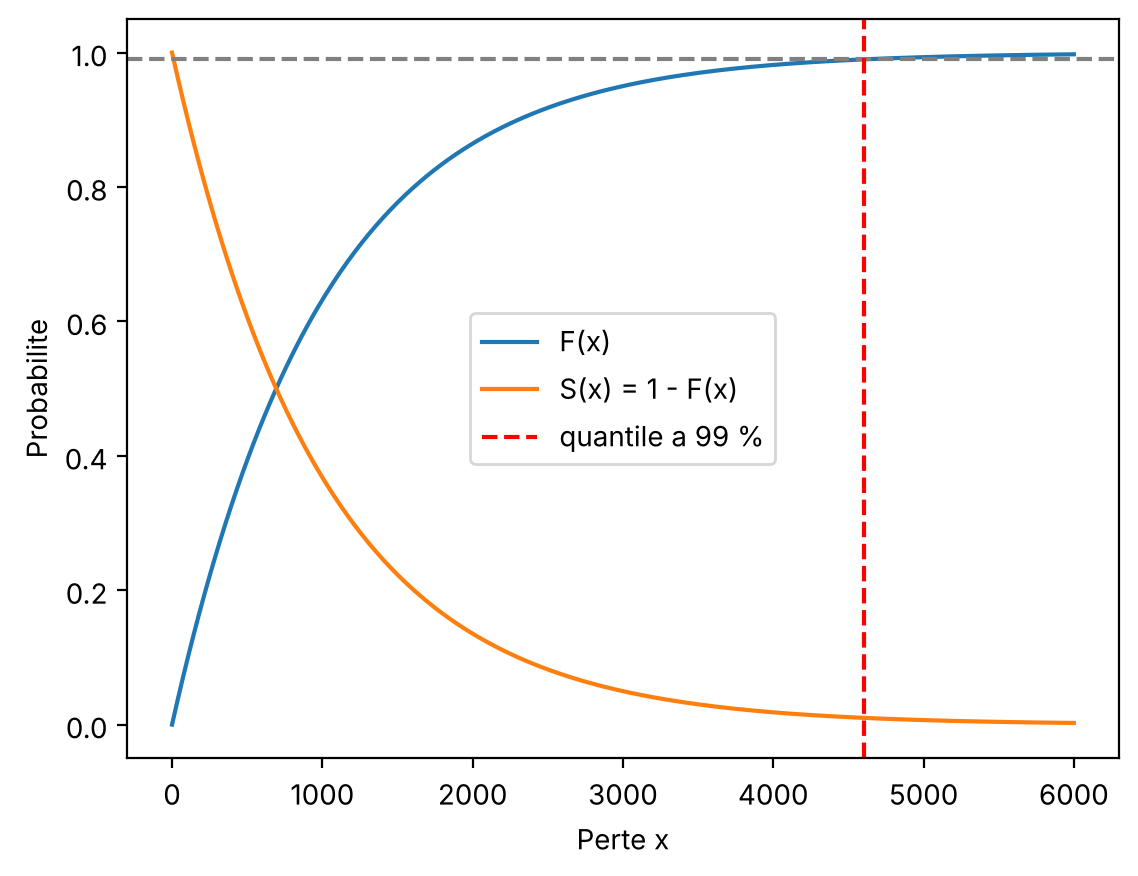

In [6]:
xs = np.linspace(0, 6000, 500)
plt.plot(xs, X.cdf(xs), label='F(x)')
plt.plot(xs, X.sf(xs), label='S(x) = 1 - F(x)')
plt.axhline(0.99, ls='--', color='grey')
plt.axvline(X.ppf(0.99), ls='--', color='red', label='quantile a 99 %')
plt.xlabel('Perte x'); plt.ylabel('Probabilite'); plt.legend(); plt.show()

## La double vérification par simulation (Monte Carlo)

In [7]:
simul = X.rvs(size=1_000_000, random_state=rng)
print('P(X > 2000) : simulation', np.mean(simul > 2000), '| exact', np.exp(-2))
print('Quantile 99 % : simulation', np.quantile(simul, 0.99), '| exact', 1000*np.log(100))

P(X > 2000) : simulation 0.135444 | exact 0.1353352832366127
Quantile 99 % : simulation 4594.076432166189 | exact 4605.170185988091


## Vérification des exercices 0.1 à 0.7

In [8]:
print('0.1 :', 2 / (1 - 0.8))
print('0.2 :', -np.log(0.005) / 0.02)
print('0.3 :', sp.integrate(x**2 * sp.exp(-x), (x, 0, sp.oo)))
print('0.4 :', sp.simplify(sp.summation(sp.exp(-lam) * lam**k / sp.factorial(k), (k, 0, sp.oo))))
E = stats.expon(scale=2)
print('0.5 :', E.cdf(3), E.sf(3))
des = rng.integers(1, 7, size=100_000)
print('0.6 :', np.mean(des == 6), '(exact 1/6 =', 1/6, ')')
d1 = rng.integers(1, 7, size=100_000); d2 = rng.integers(1, 7, size=100_000)
print('0.7 :', np.mean(d1 + d2 == 7), '(exact 1/6)')

0.1 : 10.000000000000002
0.2 : 264.9158683274018
0.3 : 2
0.4 : 1
0.5 : 0.7768698398515702 0.22313016014842982
0.6 : 0.16375 (exact 1/6 = 0.16666666666666666 )
0.7 : 0.16478 (exact 1/6)
